<!-- Project Description
This project aims to develop a machine learning model to predict employee salaries based on factors such as job title, experience, education level, skills, industry, company size, work location, remote work status, and certifications. Through comprehensive Exploratory Data Analysis (EDA), feature engineering, and predictive modeling, the project identifies the key drivers of salary growth and provides data-driven insights for workforce planning and compensation strategies.

Objective: Build an accurate salary prediction model while uncovering the most influential factors affecting employee compensation. -->

##### Project Description
This project aims to develop a machine learning model to predict employee salaries based on factors such as job title, experience, education level, skills, industry, company size, work location, remote work status, and certifications. Through comprehensive Exploratory Data Analysis (EDA), feature engineering, and predictive modeling, the project identifies the key drivers of salary growth and provides data-driven insights for workforce planning and compensation strategies.

Objective: Build an accurate salary prediction model while uncovering the most influential factors affecting employee compensation.

#### 1. Import Libraries

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns


#### 2. Load Dataset

In [2]:
df = pd.read_csv('salary_data.csv')

#### 3. Basic Understanding of Dataset

In [3]:
## cheking the first 5 rows of the dataset

df.head()

,employee_id,job_title,experience_years,education_level,skills_count,industry,company_size,location,remote_work,certifications,salary
0,EMP00001,AI Engineer,10,Bachelor,2,Healthcare,Medium,India,Hybrid,2,109413
1,EMP00002,Data Analyst,5,Bachelor,17,Telecom,Small,Australia,No,0,93764
2,EMP00003,Frontend Developer,18,PhD,4,Media,Medium,Singapore,No,1,148123
3,EMP00004,Business Analyst,19,PhD,13,Retail,Medium,Canada,Yes,0,189123
4,EMP00005,Product Manager,15,Bachelor,7,Manufacturing,Large,Sweden,Yes,0,165069


In [4]:
## Check the shape of the dataset

df.shape

(250000, 11)

In [5]:
## Checking information about the dataset

df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 250000 entries, 0 to 249999
Data columns (total 11 columns):
 #   Column            Non-Null Count   Dtype 
---  ------            --------------   ----- 
 0   employee_id       250000 non-null  object
 1   job_title         250000 non-null  object
 2   experience_years  250000 non-null  int64 
 3   education_level   250000 non-null  object
 4   skills_count      250000 non-null  int64 
 5   industry          250000 non-null  object
 6   company_size      250000 non-null  object
 7   location          250000 non-null  object
 8   remote_work       250000 non-null  object
 9   certifications    250000 non-null  int64 
 10  salary            250000 non-null  int64 
dtypes: int64(4), object(7)
memory usage: 21.0+ MB


In [6]:
## Checking columns of the dataset

df.columns

Index(['employee_id', 'job_title', 'experience_years', 'education_level',
       'skills_count', 'industry', 'company_size', 'location', 'remote_work',
       'certifications', 'salary'],
      dtype='object')

#### 4. Dataset Description

In [7]:
## checking the statistical summary of the dataset (numerical columns)

df.describe().T

,count,mean,std,min,25%,50%,75%,max
experience_years,250000.0,10.005408,6.060602,0.0,5.0,10.0,15.0,20.0
skills_count,250000.0,9.997812,5.479288,1.0,5.0,10.0,15.0,19.0
certifications,250000.0,2.491928,1.706475,0.0,1.0,2.0,4.0,5.0
salary,250000.0,145718.080524,37407.952729,31867.0,119358.0,143453.0,169492.0,333046.0


In [8]:
## checking categorical discription of the dataset (Unique values,Most frequent value(top),Frequency)

df.describe(include='object').T

,count,unique,top,freq
employee_id,250000,250000,EMP00001,1
job_title,250000,12,Backend Developer,21125
education_level,250000,5,Master,50352
industry,250000,10,Finance,25393
company_size,250000,5,Large,50254
location,250000,10,Australia,25258
remote_work,250000,3,No,83621


#### 5. Missing Value , Duplicated Value and Unique Value Analysis

In [9]:
## Checking for null values in the dataset

df.isnull().sum()

employee_id         0
job_title           0
experience_years    0
education_level     0
skills_count        0
industry            0
company_size        0
location            0
remote_work         0
certifications      0
salary              0
dtype: int64

In [10]:
## Checking duplicate values in the dataset

df.duplicated().sum()

np.int64(0)

In [11]:
## Checking the number of unique values in each column of the dataset
df.nunique()

employee_id         250000
job_title               12
experience_years        21
education_level          5
skills_count            19
industry                10
company_size             5
location                10
remote_work              3
certifications           6
salary              118956
dtype: int64

In [12]:
## Select the categorical feature from the dataset and check the unique values in it.

df.select_dtypes(include='object').nunique()

employee_id        250000
job_title              12
education_level         5
industry               10
company_size            5
location               10
remote_work             3
dtype: int64

In [13]:
## Checking the unique values

df['education_level'].unique()

array(['Bachelor', 'PhD', 'High School', 'Diploma', 'Master'],
      dtype=object)

In [14]:
df['job_title'].unique()

array(['AI Engineer', 'Data Analyst', 'Frontend Developer',
       'Business Analyst', 'Product Manager', 'Backend Developer',
       'Machine Learning Engineer', 'DevOps Engineer',
       'Software Engineer', 'Cybersecurity Analyst', 'Data Scientist',
       'Cloud Engineer'], dtype=object)

In [15]:
df['industry'].unique()

array(['Healthcare', 'Telecom', 'Media', 'Retail', 'Manufacturing',
       'Education', 'Finance', 'Technology', 'Consulting', 'Government'],
      dtype=object)

In [16]:
df['company_size'].unique()

array(['Medium', 'Small', 'Large', 'Enterprise', 'Startup'], dtype=object)

In [17]:
df['location'].unique()
    

array(['India', 'Australia', 'Singapore', 'Canada', 'Sweden', 'USA',
       'Netherlands', 'Remote', 'Germany', 'UK'], dtype=object)

In [18]:
df['remote_work'].unique()

array(['Hybrid', 'No', 'Yes'], dtype=object)

#### 6. Exploratory Data Analysis (EDA)

##### 1. Univariate Analysis

In [19]:
df.columns

Index(['employee_id', 'job_title', 'experience_years', 'education_level',
       'skills_count', 'industry', 'company_size', 'location', 'remote_work',
       'certifications', 'salary'],
      dtype='object')

In [20]:
## Dropping the employee_id column from the dataset as it is not required for analysis

df.drop(columns='employee_id', inplace=True)

In [21]:
df.columns.tolist()

['job_title',
 'experience_years',
 'education_level',
 'skills_count',
 'industry',
 'company_size',
 'location',
 'remote_work',
 'certifications',
 'salary']

In [22]:
#### Select numerical features from the dataset

num_cols = df.select_dtypes(include='number').columns

num_cols

Index(['experience_years', 'skills_count', 'certifications', 'salary'], dtype='object')

#### Checking distribustion of numerical features

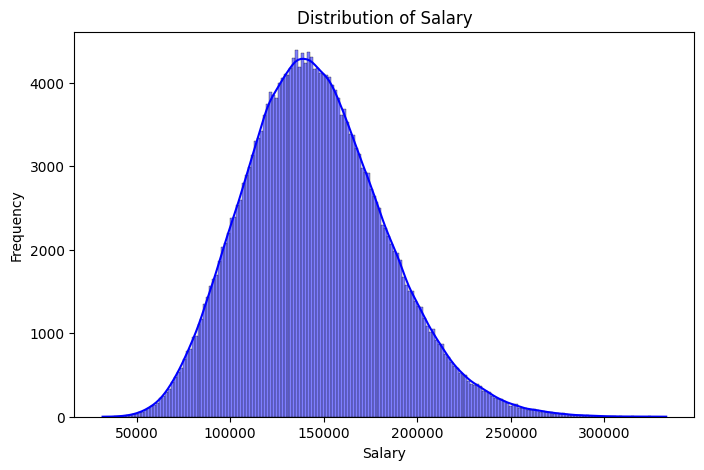

In [23]:
# Distribution of Salary

plt.figure(figsize=(8,5))
sns.histplot(df['salary'], kde=True, color='blue')

plt.title('Distribution of Salary')
plt.xlabel('Salary')
plt.ylabel('Frequency')

plt.show()

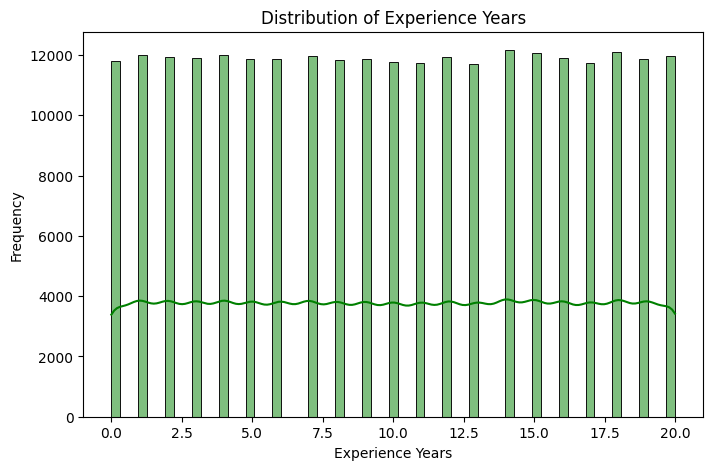

In [24]:
# Distribution of Experience Years

plt.figure(figsize=(8,5))
sns.histplot(df['experience_years'], kde=True, color='green')

plt.title('Distribution of Experience Years')
plt.xlabel('Experience Years')
plt.ylabel('Frequency')

plt.show()

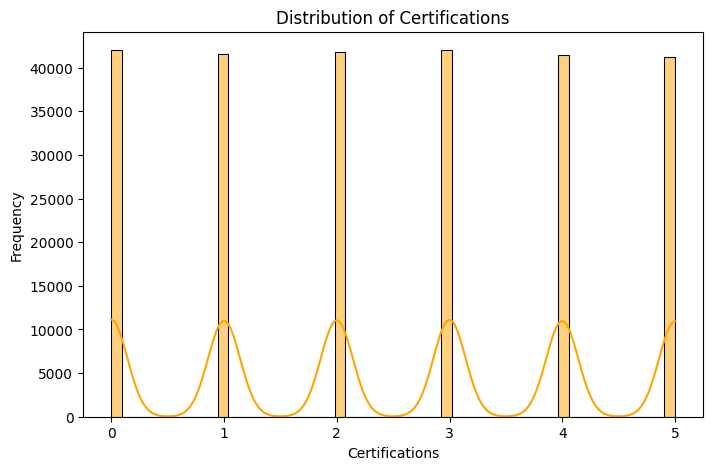

In [25]:
# Distribution of Certifications

plt.figure(figsize=(8,5))
sns.histplot(df['certifications'], kde=True, color='orange')

plt.title('Distribution of Certifications')
plt.xlabel('Certifications')
plt.ylabel('Frequency')

plt.show()

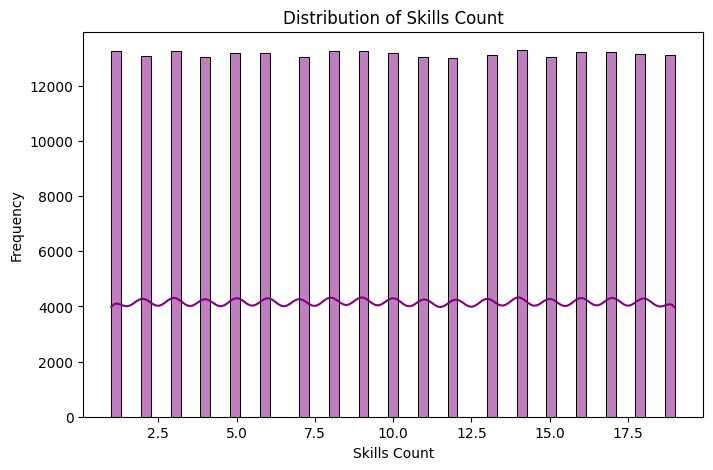

In [26]:
# Distribution of Skills Count

plt.figure(figsize=(8,5))
sns.histplot(df['skills_count'], kde=True, color='purple')

plt.title('Distribution of Skills Count')
plt.xlabel('Skills Count')
plt.ylabel('Frequency')

plt.show()

#### Analysis of categorical features

In [27]:
## Select categorical features from the dataset
cat_cols = df.select_dtypes(include='object').columns
cat_cols

Index(['job_title', 'education_level', 'industry', 'company_size', 'location',
       'remote_work'],
      dtype='object')

In [28]:
## checking values of the categorical features in the dataset for all categorical features in table formate

cat_cols = df.select_dtypes(include='object').columns

categorical_info = []

for col in cat_cols:
    categorical_info.append({
        'Feature': col,
        'Unique Values Count': df[col].nunique(),
        'Sample Values': ', '.join(map(str, df[col].unique()[:4]))
    })

cat_summary = pd.DataFrame(categorical_info)

cat_summary


,Feature,Unique Values Count,Sample Values
0,job_title,12,"AI Engineer, Data Analyst, Frontend Developer,..."
1,education_level,5,"Bachelor, PhD, High School, Diploma"
2,industry,10,"Healthcare, Telecom, Media, Retail"
3,company_size,5,"Medium, Small, Large, Enterprise"
4,location,10,"India, Australia, Singapore, Canada"
5,remote_work,3,"Hybrid, No, Yes"


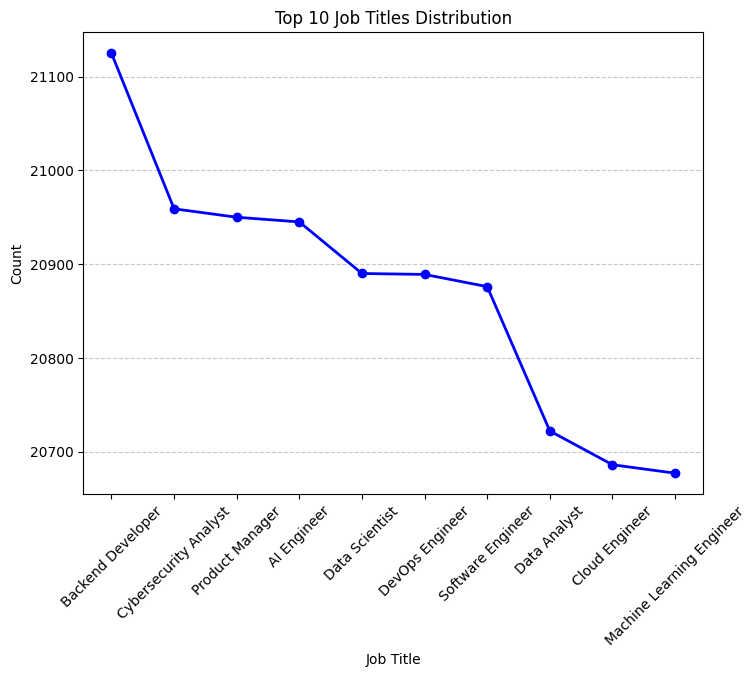

In [63]:
## Create a bar plot one by one for each categorical feature in the dataset to visualize the distribution of unique values.
## line Plot for Job Title

# Top 10 Most Common Job Titles

top_jobs = df['job_title'].value_counts().head(10)

plt.figure(figsize=(8,6))

plt.plot(
    top_jobs.index,
    top_jobs.values,
    marker='o',
    color='blue',
    linewidth=2
)

plt.title('Top 10 Job Titles Distribution')
plt.xlabel('Job Title')
plt.ylabel('Count')

plt.xticks(rotation=45)
plt.grid(axis='y', linestyle='--', alpha=0.7)

plt.show()



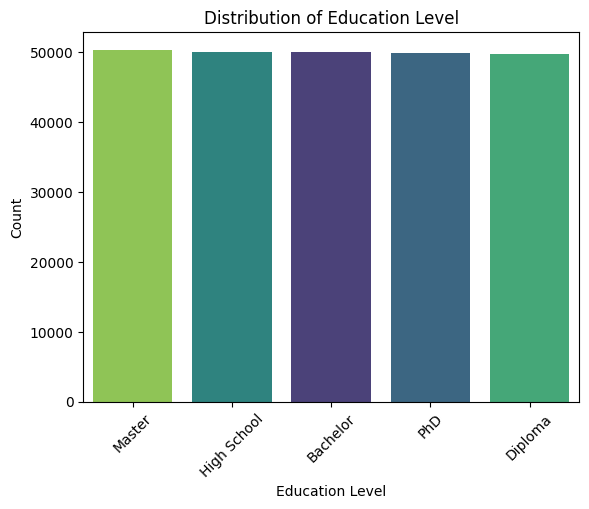

In [30]:
## Bar plot for Education Level
sns.countplot(
    data=df,
    x='education_level',
    hue='education_level',
    order=df['education_level'].value_counts().index,
    palette='viridis',
    legend=False
)
plt.title('Distribution of Education Level')
plt.xlabel('Education Level')
plt.ylabel('Count')
plt.xticks(rotation=45)
plt.show()


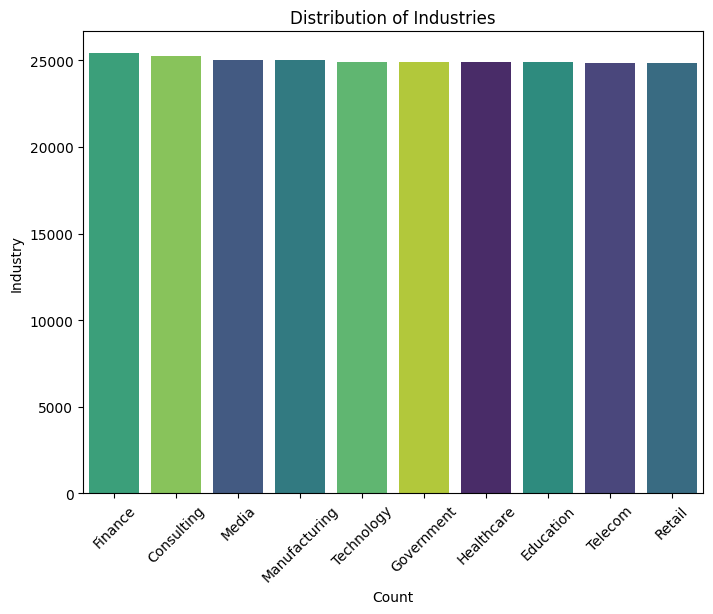

In [64]:
## Bar plot for Industry
plt.figure(figsize=(8, 6))
sns.countplot(
    data=df,
    x='industry',
    hue='industry',
    order=df['industry'].value_counts().index,
    palette='viridis',
    legend=False
)
plt.title('Distribution of Industries')
plt.xlabel('Count')
plt.ylabel('Industry')
plt.xticks(rotation=45)
plt.show()


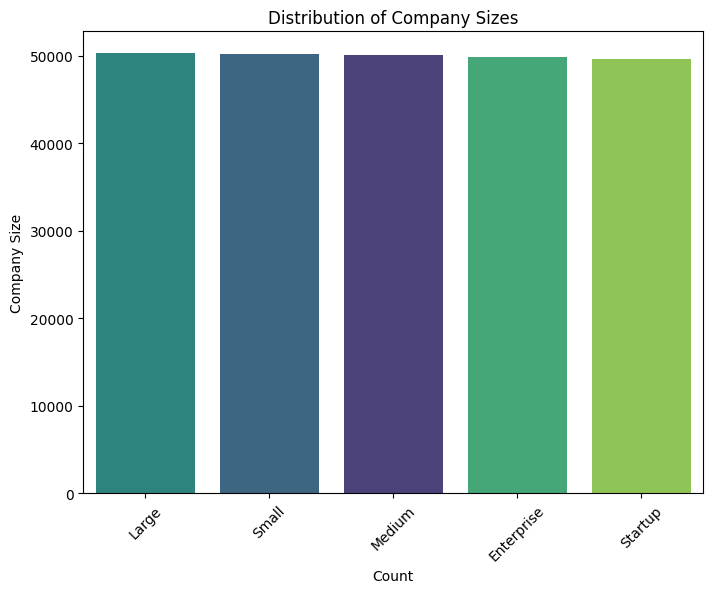

In [65]:
## Bar plot for compony size
plt.figure(figsize=(8, 6))
sns.countplot(
    data=df,
    x='company_size',
    hue='company_size',
    order=df['company_size'].value_counts().index,
    palette='viridis',
    legend=False
)
plt.title('Distribution of Company Sizes')
plt.xlabel('Count')
plt.ylabel('Company Size')
plt.xticks(rotation=45)
plt.show()

#### 2. Multivariate Analysis 

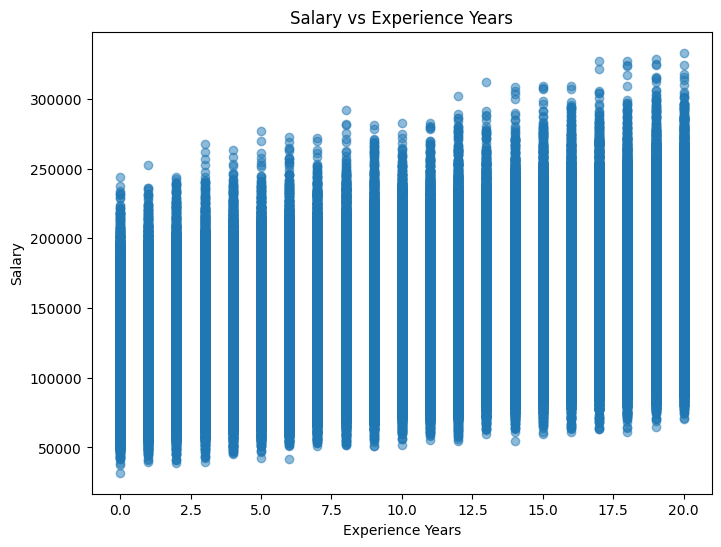

In [33]:
## Analyzing salary vs experience_years
plt.figure(figsize=(8, 6))
plt.scatter(df['experience_years'], df['salary'], alpha=0.5)
plt.title('Salary vs Experience Years')
plt.xlabel('Experience Years')
plt.ylabel('Salary')
plt.show()

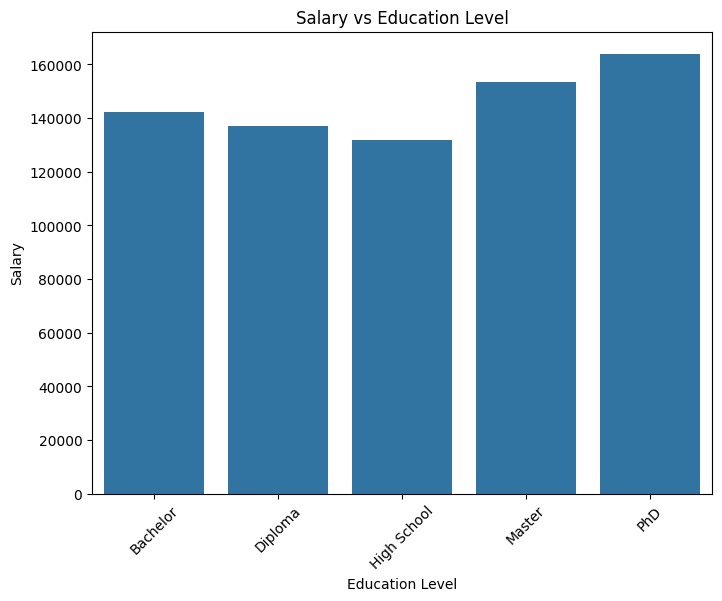

In [34]:
## Analyzing salary vs Education Level
plt.figure(figsize=(8, 6))
edu_salary = df.groupby('education_level')['salary'].mean().reset_index()
sns.barplot(data=edu_salary, x='education_level', y='salary')   
plt.title('Salary vs Education Level')
plt.xlabel('Education Level')
plt.ylabel('Salary')
plt.xticks(rotation=45)
plt.show()

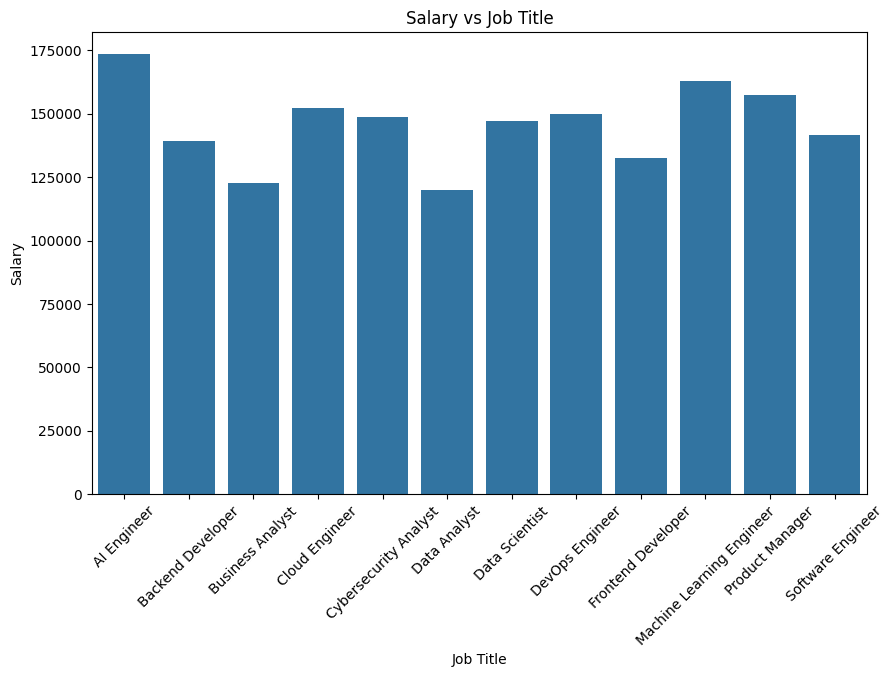

In [35]:
## Analizing salary vs Job Title
plt.figure(figsize=(10, 6))
job_salary = df.groupby('job_title')['salary'].mean().reset_index()
sns.barplot(data=job_salary, x='job_title', y='salary')
plt.title('Salary vs Job Title')
plt.xlabel('Job Title')
plt.ylabel('Salary')
plt.xticks(rotation=45)
plt.show()

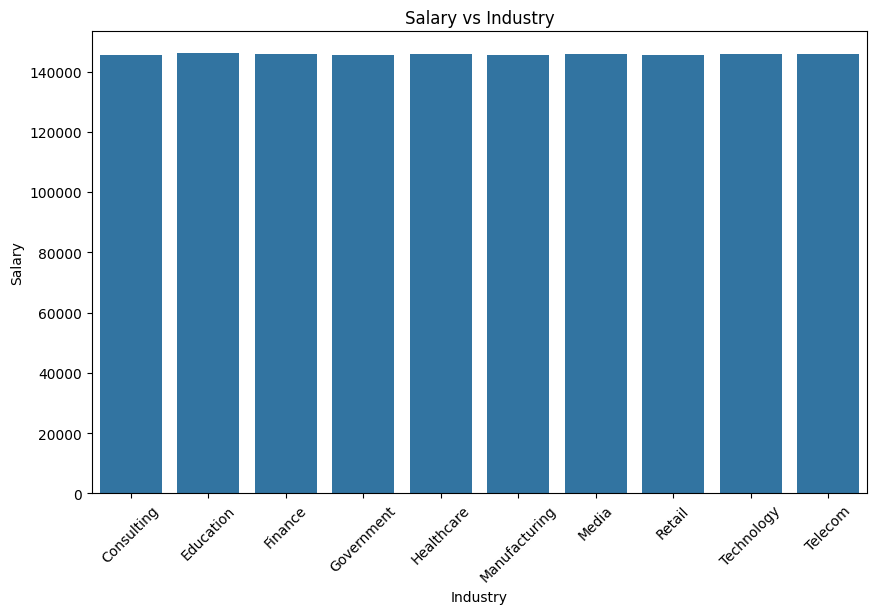

In [36]:
## Analyzing the salary vs Industry
plt.figure(figsize=(10, 6))
industry_salary = df.groupby('industry')['salary'].mean().reset_index()
sns.barplot(data=industry_salary, x='industry', y='salary')
plt.title('Salary vs Industry')
plt.xlabel('Industry')
plt.ylabel('Salary')
plt.xticks(rotation=45)
plt.show()

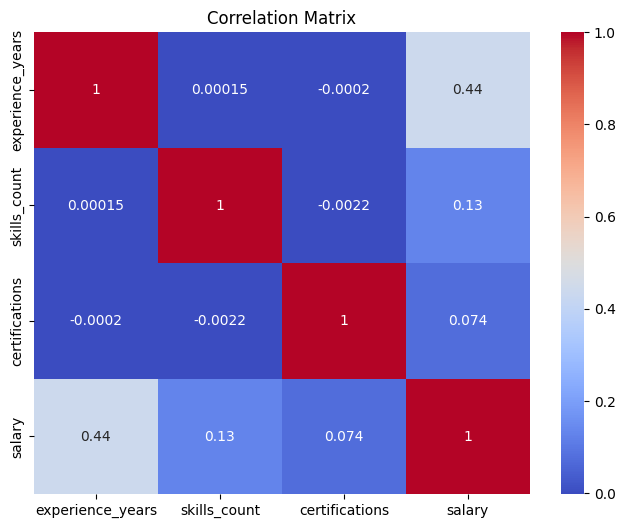

In [37]:
#### Checking the correlation between numerical features in the dataset
plt.figure(figsize=(8, 6))
sns.heatmap(df[num_cols].corr(), annot=True, cmap='coolwarm')
plt.title('Correlation Matrix')
plt.show()

#### 7. Data Preprocessing , Feature Engineering and Model Building

#### Checking Outlier in dataset

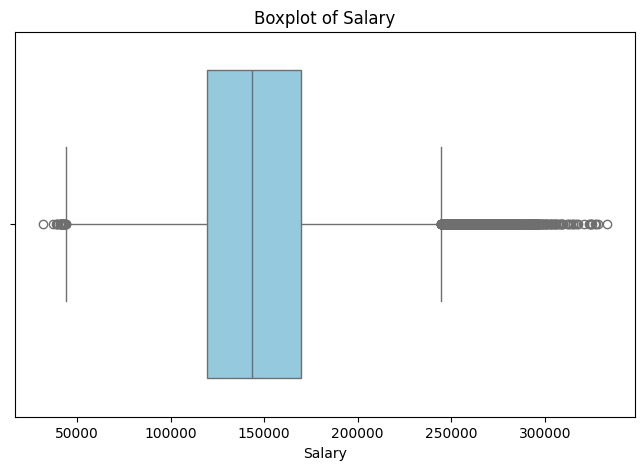

In [43]:
# Boxplot of Salary

plt.figure(figsize=(8,5))
sns.boxplot(x=df['salary'], color='skyblue')

plt.title('Boxplot of Salary')
plt.xlabel('Salary')

plt.show()

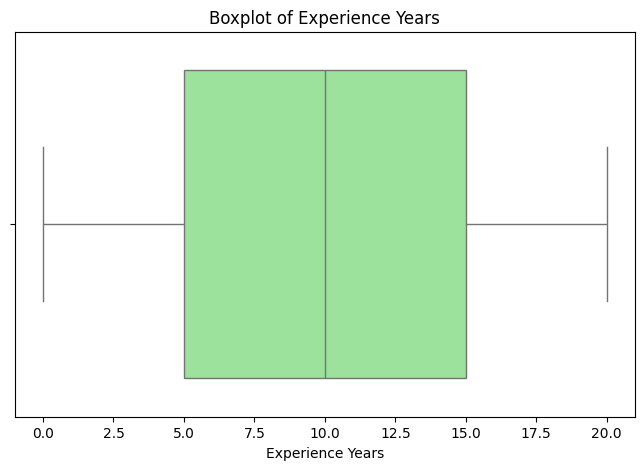

In [44]:
# Boxplot of Experience Years

plt.figure(figsize=(8,5))
sns.boxplot(x=df['experience_years'], color='lightgreen')

plt.title('Boxplot of Experience Years')
plt.xlabel('Experience Years')

plt.show()

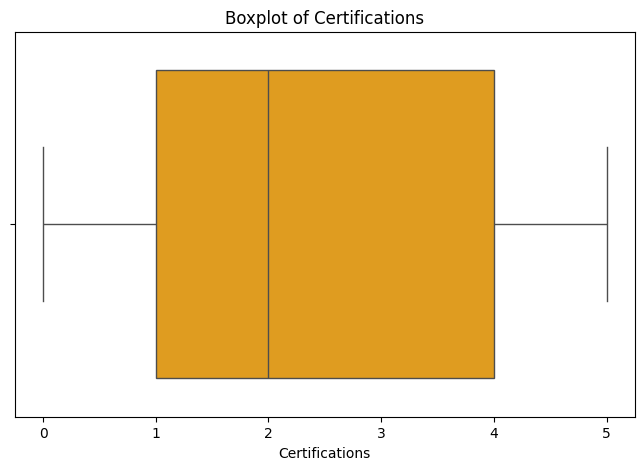

In [39]:
# Boxplot of Certifications

plt.figure(figsize=(8,5))
sns.boxplot(x=df['certifications'], color='orange')

plt.title('Boxplot of Certifications')
plt.xlabel('Certifications')

plt.show()

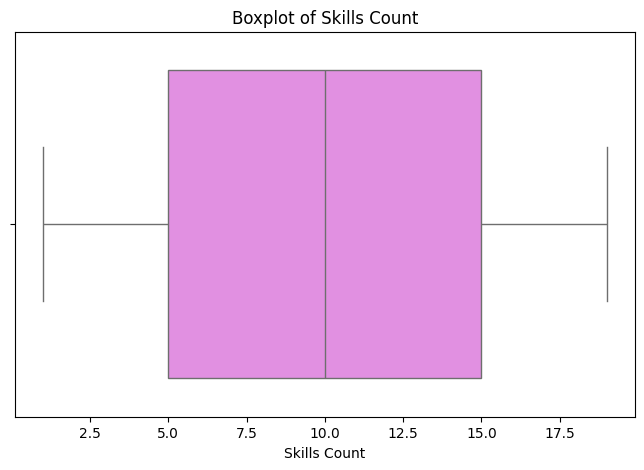

In [40]:
# Boxplot of Skills Count

plt.figure(figsize=(8,5))
sns.boxplot(x=df['skills_count'], color='violet')

plt.title('Boxplot of Skills Count')
plt.xlabel('Skills Count')

plt.show()

In [41]:
# Summary statistics for numerical features

df[['salary',
    'experience_years',
    'certifications',
    'skills_count']].describe().T

,count,mean,std,min,25%,50%,75%,max
salary,250000.0,145718.080524,37407.952729,31867.0,119358.0,143453.0,169492.0,333046.0
experience_years,250000.0,10.005408,6.060602,0.0,5.0,10.0,15.0,20.0
certifications,250000.0,2.491928,1.706475,0.0,1.0,2.0,4.0,5.0
skills_count,250000.0,9.997812,5.479288,1.0,5.0,10.0,15.0,19.0


In [ ]:
#### Handle Outliers in the numerical features using IQR method
Q1 = df[num_cols].quantile(0.25)
Q3 = df[num_cols].quantile(0.75)
IQR = Q3 - Q1
lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

print("Lower Bound:\n", lower_bound)
print("\nUpper Bound:\n", upper_bound)


    


Lower Bound:
 experience_years      -10.0
skills_count          -10.0
certifications         -3.5
salary              44157.0
dtype: float64

Upper Bound:
 experience_years        30.0
skills_count            30.0
certifications           8.5
salary              244693.0
dtype: float64


In [ ]:
### Capping the outliers in the numerical features using IQR method
for col in num_cols:
    df[col] = np.where(df[col] < lower_bound[col], lower_bound[col], df[col])
    df[col] = np.where(df[col] > upper_bound[col], upper_bound[col], df[col])
    
print("Outliers have been capped using the IQR method.")

Outliers have been capped using the IQR method.


In [ ]:
### Check lower and upper bounds after capping the outliers
Q1_after = df[num_cols].quantile(0.25)
Q3_after = df[num_cols].quantile(0.75)
IQR_after = Q3_after - Q1_after

print("Lower Bound after capping:\n", Q1_after)
print("\nUpper Bound after capping:\n", Q3_after)
print("\nIQR after capping:\n", IQR_after)


Lower Bound after capping:
 experience_years         5.0
skills_count             5.0
certifications           1.0
salary              119358.0
Name: 0.25, dtype: float64

Upper Bound after capping:
 experience_years        15.0
skills_count            15.0
certifications           4.0
salary              169492.0
Name: 0.75, dtype: float64

IQR after capping:
 experience_years       10.0
skills_count           10.0
certifications          3.0
salary              50134.0
dtype: float64


In [ ]:
### Saving the cleaned dataset to a new CSV file
df.to_csv('cleaned_salary_data.csv', index=False)
print("Cleaned dataset saved to 'cleaned_salary_data.csv'")

Cleaned dataset saved to 'cleaned_salary_data.csv'


## Import libraries from load cleaned dataset

In [47]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [48]:
new_df = pd.read_csv('cleaned_salary_data.csv')

In [49]:
new_df.head()

,job_title,experience_years,education_level,skills_count,industry,company_size,location,remote_work,certifications,salary
0,AI Engineer,10.0,Bachelor,2.0,Healthcare,Medium,India,Hybrid,2.0,109413.0
1,Data Analyst,5.0,Bachelor,17.0,Telecom,Small,Australia,No,0.0,93764.0
2,Frontend Developer,18.0,PhD,4.0,Media,Medium,Singapore,No,1.0,148123.0
3,Business Analyst,19.0,PhD,13.0,Retail,Medium,Canada,Yes,0.0,189123.0
4,Product Manager,15.0,Bachelor,7.0,Manufacturing,Large,Sweden,Yes,0.0,165069.0


In [50]:
## Import Libraries for data preprocessing , feature engineering and model building
from sklearn.preprocessing import LabelEncoder, OneHotEncoder, StandardScaler,OrdinalEncoder
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score
from sklearn.tree import DecisionTreeRegressor
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer



In [51]:
### Splitting the dataset into features and target variable
X = new_df.drop(columns='salary')
y = new_df['salary']


In [52]:
### Train-test split of the dataset
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

In [53]:
#### Select numerical feature from cleaned dataset
num_features = X_train.select_dtypes(include='number').columns


#### Select categorical feature from cleaned dataset    
cat_features = X_train.select_dtypes(include='object').columns


In [54]:
#### Creating Pipeline for preprocessing and model building

## Creating a preprocessing pipeline for numerical features

num_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

## Creating a preprocessing pipeline for categorical features

cat_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='constant', fill_value='missing')),
    ('onehot', OneHotEncoder(drop='first',handle_unknown='ignore' ))
])
    


### Combining the numerical and categorical pipelines into a single preprocessing pipeline

preprocessor = ColumnTransformer([
    ('num', num_pipeline, num_features),
    ('cat', cat_pipeline, cat_features)
])

## Create model pipeline with preprocessing and model building steps

lr_pipeline = Pipeline([
    ('preprocessor', preprocessor),
    ('regressor', LinearRegression())
])
lr_pipeline


,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('regressor', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, default=0.3If

In [55]:
## Fitting the model pipeline on the cleaned dataset
lr_pipeline.fit(X_train, y_train)
lr_pipeline



,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('regressor', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](9,)","['job_title','experience_years','education_level',...,'location', 'remote_work','certifications']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,9
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed thr

In [56]:
## predicting data
y_pred = lr_pipeline.predict(X_test)

In [57]:
## Checking r2 score and mean squared error and mean squared error of the model
r2 = r2_score(y_test, y_pred)
rmse = (mean_squared_error(y_test, y_pred))**0.5

print(f"R2 Score: {r2}")
print(f"Root Mean Squared Error: {rmse}")

R2 Score: 0.9650207885364436
Root Mean Squared Error: 6893.723314980876


In [58]:
## Creating a pipeline with preprocessing and model building steps using DecisionTreeRegressor
dt_pipeline = Pipeline([
    ('preprocessor', preprocessor),
    ('model', DecisionTreeRegressor(
        max_depth=5,
        random_state=42
    ))
])



In [59]:
## Fitting the model pipeline on the cleaned dataset
dt_pipeline.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](9,)","['job_title','experience_years','education_level',...,'location', 'remote_work','certifications']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,9
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through

In [60]:
## Predicting the salary on the test dataset using the fitted model pipeline
y_pred = dt_pipeline.predict(X_test)


In [61]:
## Check r2 score and mean squared error of the DecisionTreeRegressor model
r2 = r2_score(y_test, y_pred)
rmse = (mean_squared_error(y_test, y_pred))**0.5

print(f"R2 Score: {r2}")
print(f"Root Mean Squared Error: {rmse}")

R2 Score: 0.5333635464584907
Root Mean Squared Error: 25178.982302595465


##### We can see that the DecisionTreeRegressor model has a lower R2 score and higher root mean squared error compared to the LinearRegression model, indicating that LR performs better on this dataset.
##### So we will use the LinearRegression model for this dataset.

In [62]:
## create pickle file of the model pipeline where we use LinearRegression models for salary prediction
import pickle

with open('lr_model.pkl', 'wb') as f:
    pickle.dump(lr_pipeline, f)